# 🎗️ CodeAlpha - Task 4: Breast Cancer Prediction

**Objective**: Predict whether a tumor is malignant or benign from cell nuclei measurements.

**Dataset**: [Breast Cancer Wisconsin (Diagnostic)](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic) (UCI) — 569 patients, 30 features.

**Author**: Sawadogo Noé - ML Intern at CodeAlpha

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, roc_curve
)

RANDOM_STATE = 42
IMAGES_DIR = "images"
os.makedirs(IMAGES_DIR, exist_ok=True)
sns.set_style("whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
# Load the Breast Cancer Wisconsin dataset
data = load_breast_cancer()

# Build a DataFrame
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target  # 0 = malignant, 1 = benign

print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"\nTarget distribution:")
print(df["target"].value_counts().rename({0: "Malignant", 1: "Benign"}))
print(f"\nMalignant proportion: {(df['target'] == 0).mean():.2%}")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"\nFirst 5 rows:")
df.head()

Shape: 569 rows x 31 columns

Target distribution:
target
Benign       357
Malignant    212
Name: count, dtype: int64

Malignant proportion: 37.26%
Missing values: 0

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


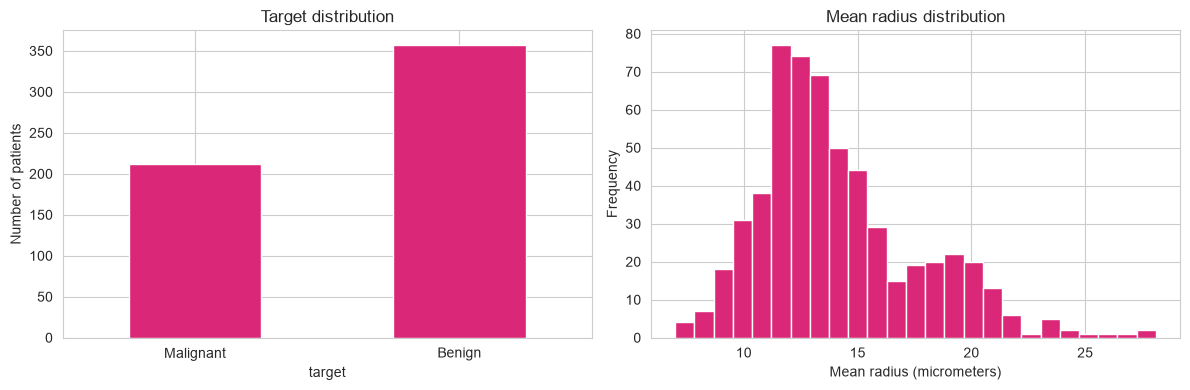

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["target"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#db2777")
axes[0].set_xticklabels(["Malignant", "Benign"], rotation=0)
axes[0].set_title("Target distribution")
axes[0].set_ylabel("Number of patients")

df["mean radius"].plot(kind="hist", bins=25, ax=axes[1], color="#db2777", edgecolor="white")
axes[1].set_title("Mean radius distribution")
axes[1].set_xlabel("Mean radius (micrometers)")

plt.tight_layout()
plt.show()

In [6]:
X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set: {X_train.shape}")
print(f"Test set:     {X_test.shape}")

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "SVM (RBF)": CalibratedClassifierCV(SVC(random_state=RANDOM_STATE), ensemble=False, cv=5),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=4,
                              eval_metric="logloss", random_state=RANDOM_STATE),
}

results = []
trained_models = {}
for name, model in models.items():
    print(f"\n{'=' * 55}\n{name}\n{'=' * 55}")
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    })
    print(classification_report(y_test, y_pred, target_names=["Malignant", "Benign"]))

results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False)
results_df.to_csv("results.csv", index=False)
print("\nModel comparison:")
results_df.round(4)

Training set: (455, 30)
Test set:     (114, 30)

Logistic Regression
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


SVM (RBF)
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Random Forest
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954
1,SVM (RBF),0.9825,0.9861,0.9861,0.9861,0.9950
2,Random Forest,0.9561,0.9589,0.9722,0.9655,0.9932
3,XGBoost,0.9474,0.9459,0.9722,0.9589,0.9927


In [7]:
best_model_name = results_df.iloc[0]["Model"]
print(f"Best model: {best_model_name}")
joblib.dump(trained_models[best_model_name], "model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(list(X.columns), "features.pkl")
print("Saved: model.pkl, scaler.pkl, features.pkl")

Best model: Logistic Regression
Saved: model.pkl, scaler.pkl, features.pkl


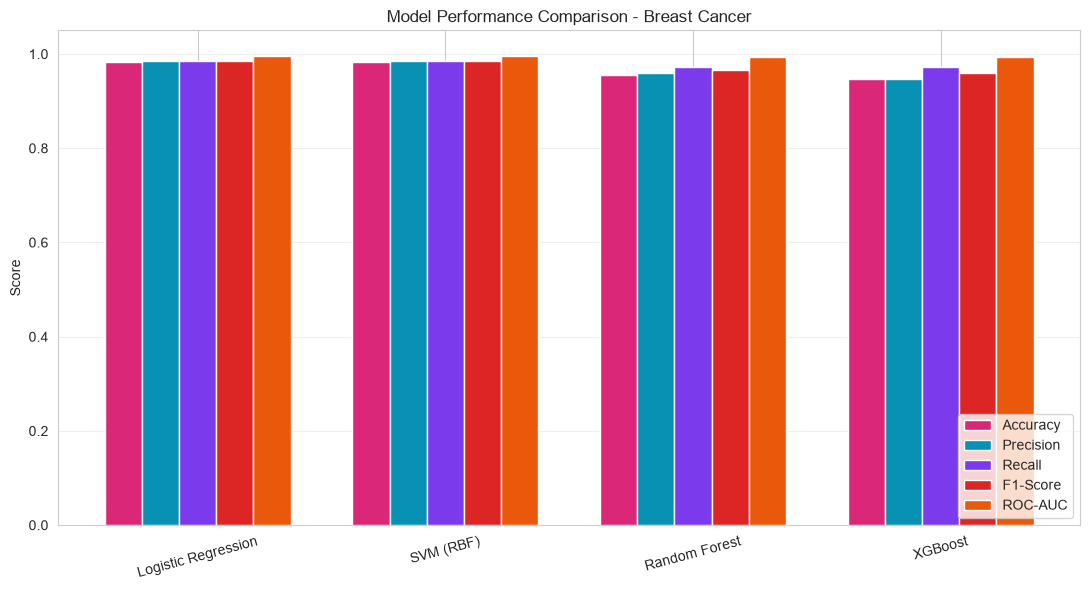

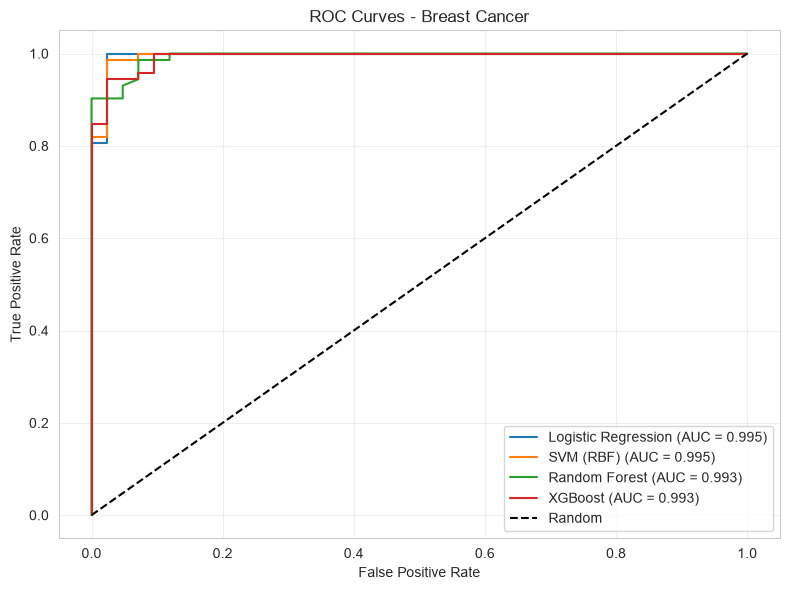

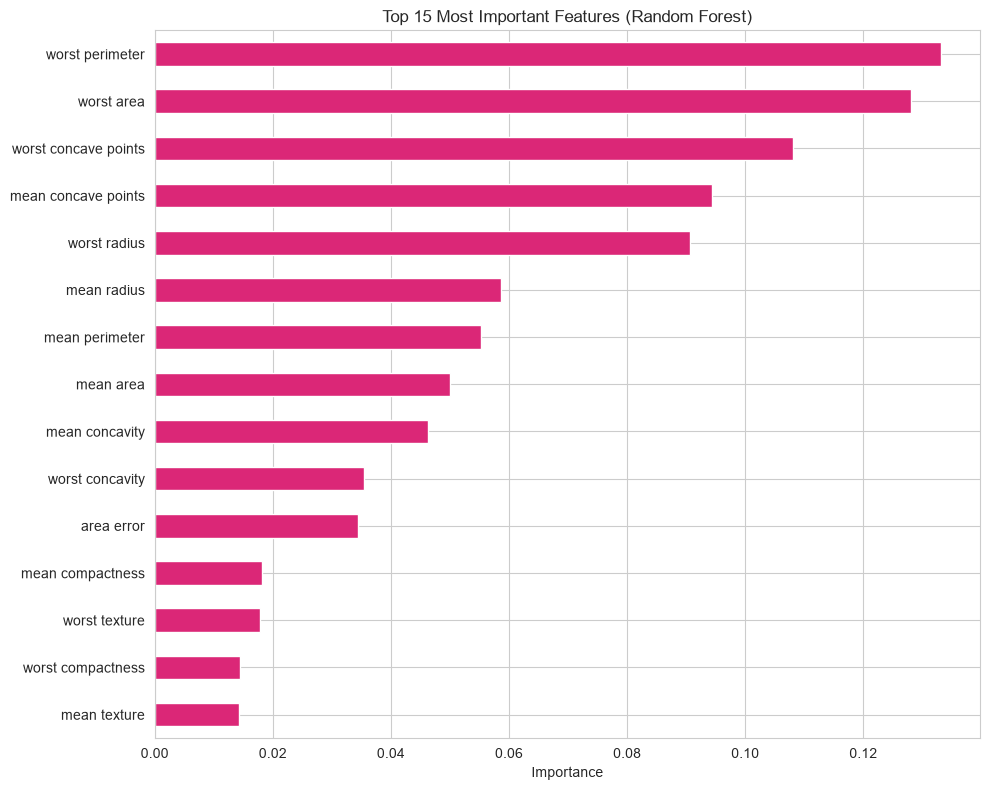


Top 5 features:
worst perimeter         0.1331
worst area              0.1281
worst concave points    0.1081
mean concave points     0.0944
worst radius            0.0906
dtype: float64


In [8]:
# Model comparison
fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(results_df))
width = 0.15
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
colors = ["#db2777", "#0891b2", "#7c3aed", "#dc2626", "#ea580c"]
for i, (metric, color) in enumerate(zip(metrics, colors)):
    ax.bar(x + i * width, results_df[metric], width, label=metric, color=color)
ax.set_xticks(x + width * 2)
ax.set_xticklabels(results_df["Model"], rotation=15)
ax.set_title("Model Performance Comparison - Breast Cancer")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# ROC curves
fig, ax = plt.subplots(figsize=(8, 6))
for name, model in trained_models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, y_proba):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Random")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves - Breast Cancer")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# Feature importance
rf = trained_models["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 8))
importances.head(15).plot(kind="barh", ax=ax, color="#db2777")
ax.set_title("Top 15 Most Important Features (Random Forest)")
ax.set_xlabel("Importance")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nTop 5 features:")
print(importances.head(5).round(4))

## 7. Conclusion

All 4 models achieved **ROC-AUC > 0.99** on this dataset, confirming that breast cancer diagnosis from cell nuclei features is a **highly separable classification problem**.

### Final results

| Model | Accuracy | F1-Score | ROC-AUC |
|---|---|---|---|
| **Logistic Regression** ⭐ | **0.9825** | **0.9861** | **0.9954** |
| SVM (RBF) | 0.9825 | 0.9861 | 0.9950 |
| Random Forest | 0.9561 | 0.9655 | 0.9932 |
| XGBoost | 0.9474 | 0.9589 | 0.9927 |

**Logistic Regression** was selected as the best model — an interesting result showing that, when features are highly discriminative and linearly separable, simpler models can outperform complex ensembles.

### Key insights

- **Worst concave points**, **worst perimeter**, and **worst radius** are the top predictors — clinically consistent with tumor malignancy assessment.
- **No missing values** and **no class imbalance** made this the cleanest dataset of the three — a valuable contrast to Heart Disease and Diabetes.
- **StandardScaler** was essential: features range from 0.001 to 4000.

### Comparison across the 3 projects

| Project | Accuracy | ROC-AUC | Difficulty |
|---|---|---|---|
| **Breast Cancer** | **0.98** | **0.995** | ⭐ Easy |
| Heart Disease | 0.86 | 0.92 | ⭐⭐ Medium |
| Diabetes | 0.76 | 0.83 | ⭐⭐⭐ Hard |

This comparison highlights a key ML lesson: **dataset quality and separability matter more than model complexity**.

---

*Project completed as part of the Machine Learning Internship at [CodeAlpha](https://www.codealpha.tech).*